# Deep Hedging on Real SPX Options (Databento OPRA data)
**AMS 520 · Hetvi Soni** — companion notebook to `Phase2_EDA_and_Deep_Hedging.ipynb`

So far the option we hedged was a *made-up* contract (strike 100, 1 month) on real or simulated SPY prices, and we never knew
what the bank would have been paid for it. This notebook uses **real S&P 500 index options (SPX)** traded on US exchanges:

1. Every month from 2019 onward, we "sell" the real 1-month at-the-money **SPX call** at its **real market price** (the premium).
2. We hedge it until expiry with every strategy from Phase II (Black–Scholes, Leland, Whalley–Wilmott, deep hedging).
3. We measure the **real profit and loss**: premium received − payoff owed + trading gains − transaction costs.

**Why SPX:** SPX options are **European** and cash-settled, exactly like the option in our model. (Options on SPY are American.)

### Data budget — hard limit of $125 (free Databento credit)
* **Dry run first:** with `DRY_RUN = True` the notebook only asks Databento for the *price* of each request (free) and prints the total.
  Nothing is downloaded and nothing is charged.
* **Budget cap:** downloading stops if the running total would exceed `BUDGET_USD` (default **$20**, far below $125).
* **Cache:** every downloaded file is saved in `data/raw/databento/`. If the file exists, it is reused, so re-running never pays twice.
  **Download this folder** when you are done (zip cell at the end) and upload it next time.
* We only request a tiny slice of the market: a handful of SPX contracts, a few minutes per month.

## 1. Setup

In [1]:
%pip install -q databento yfinance
import os, json, time, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.optimize import brentq
import torch, torch.nn as nn

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3})
for d in ["data/raw/databento", "figures", "results"]:
    os.makedirs(d, exist_ok=True)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

In [2]:
# ---------------- Budget and safety settings ----------------
DRY_RUN = False          # True = only estimate the cost (free). Set to False ONLY after checking the estimate.
BUDGET_USD = 20.0       # hard cap for this notebook (your free credit is $125)
CACHE_DIR = "data/raw/databento"

# ---------------- Problem settings (same as Phase II) ----------------
TRADING_DAYS, N_STEPS = 252, 21
DT = 1 / TRADING_DAYS; T = N_STEPS * DT
K_NORM = 100.0                    # every contract is rescaled so that its strike = 100
ALPHA = 0.95
COSTS = [0.001, 0.005]
TEST_START, TEST_END = "2019-01-01", "2026-09-30"
TRAIN_END = "2018-12-31"
DATASET, PARENT, ROOT = "OPRA.PILLAR", "SPX.OPT", "SPX"   # SPX = standard monthly, European, AM-settled
N_STRIKES = 3                     # strikes closest to the money that we price (we keep the closest)
QUOTE_WINDOW = ("15:30", "16:00") # New York time: last 30 minutes before the stock market close

## 2. Connect to Databento (API key from Colab Secrets — never written in the notebook)

In Colab: click the **key icon** in the left sidebar → **Add new secret** → Name `DATABENTO_API_KEY`, Value = your key →
switch on **Notebook access**. The key then never appears in the notebook or on GitHub.

In [3]:
import databento as db
try:
    from google.colab import userdata
    API_KEY = userdata.get("DATABENTO_API_KEY")
except Exception:
    from getpass import getpass
    API_KEY = os.environ.get("DATABENTO_API_KEY") or getpass("Databento API key: ")
client = db.Historical(API_KEY)
print("Connected to Databento.")

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Connected to Databento.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [4]:
spent = {"estimated_total": 0.0, "downloaded": 0.0, "requests": 0, "cache_hits": 0}
failed = []

def with_retries(fn, what, retries=3):
    # Databento occasionally returns temporary server errors (500/504): wait and try again
    for attempt in range(1, retries + 1):
        try:
            return fn()
        except Exception as e:
            if attempt == retries:
                print(f"  {what}: failed {retries} times ({type(e).__name__}); skipped for now, will retry next run")
                return None
            wait = 15 * attempt
            print(f"  {what}: attempt {attempt} failed ({type(e).__name__}), retrying in {wait}s")
            time.sleep(wait)

def fetch(name, **query):
    # Download one Databento request with: cache -> free cost check -> budget check -> download (with retries).
    path = os.path.join(CACHE_DIR, f"{name}.csv")
    if os.path.exists(path):
        spent["cache_hits"] += 1
        return pd.read_csv(path)
    cost = with_retries(lambda: float(client.metadata.get_cost(**query)), f"{name} (price check)")
    if cost is None:
        failed.append(name); return None
    spent["estimated_total"] += cost; spent["requests"] += 1
    if DRY_RUN:
        return None
    if spent["downloaded"] + cost > BUDGET_USD:
        raise RuntimeError(f"Budget stop: this request costs ${cost:.4f}, already downloaded ${spent['downloaded']:.2f}, "
                           f"cap ${BUDGET_USD:.2f}. Nothing was downloaded.")
    df = with_retries(lambda: client.timeseries.get_range(**query).to_df().reset_index(), name)
    if df is None:
        failed.append(name); return None
    spent["downloaded"] += cost
    df.to_csv(path, index=False)
    return df

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

## 3. Market data we already have: S&P 500 index, VIX and rates

* **SPX index level** (`^GSPC`) from Yahoo Finance: daily open and close. The open of the expiry day approximates the official
  settlement price (SPX monthly options settle on the *opening* prices of the index stocks).
* **VIX and risk-free rate** from the Phase I file `data/processed/market_daily_clean.csv` (upload it like in Phase II).

In [5]:
import yfinance as yf
gspc = yf.download("^GSPC", start="2004-12-01", end="2026-10-31", auto_adjust=False, progress=False)
if isinstance(gspc.columns, pd.MultiIndex):
    gspc.columns = gspc.columns.get_level_values(0)
gspc.index = pd.to_datetime(gspc.index).tz_localize(None)
gspc = gspc[["Open", "Close"]].dropna()

mkt = pd.read_csv("data/processed/market_daily_clean.csv", index_col="date", parse_dates=True)
print(f"SPX index: {gspc.index.min().date()} to {gspc.index.max().date()} | VIX/rates: {len(mkt):,} days")

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

SPX index: 2004-12-01 to 2026-10-30 | VIX/rates: 5,468 days


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

## 4. Choosing the contracts (one per month)

For each month we take the standard monthly SPX expiry (normally the 3rd Friday), go back **21 trading days** to the *sale date*,
and on that day pick the call whose strike is closest to the index level (at the money).

Two small requests per month:
1. **`definition`** on the sale date: the list of SPX contracts that exist (strike, expiry, call/put).
2. **`cbbo-1m`** (best bid and ask, one-minute bars) for the chosen call and put during the last 30 minutes of the sale date.
   The **mid price** (average of bid and ask) is the premium. The put is used only to compute a clean implied volatility.

In [6]:
def third_friday(year, month):
    d = pd.Timestamp(year=year, month=month, day=15)
    return d + pd.Timedelta(days=(4 - d.weekday()) % 7)

def parse_occ(sym):
    # OCC symbol: ROOT(6) YYMMDD C/P STRIKE*1000(8), e.g. 'SPX   240119C04800000'
    sym = str(sym)
    return {"root": sym[:6].strip(), "expiry": pd.Timestamp("20" + sym[6:12]),
            "cp": sym[12], "strike": int(sym[13:21]) / 1000.0}

days = gspc.index
plan = []
for m in pd.period_range(TEST_START, TEST_END, freq="M"):
    tf = third_friday(m.year, m.month)
    on_or_before = days[days <= tf]
    if len(on_or_before) < N_STEPS + 1:
        continue
    expiry_day = on_or_before[-1]                     # 3rd Friday, or Thursday if Friday is a holiday
    sale = days[days.get_loc(expiry_day) - N_STEPS]
    if sale < pd.Timestamp(TEST_START) or expiry_day > days[-1]:
        continue
    plan.append({"month": str(m), "sale_date": sale, "expiry_target": tf, "expiry_day": expiry_day})
plan = pd.DataFrame(plan)
print(f"{len(plan)} monthly contracts planned, first sale {plan.sale_date.min().date()}, last {plan.sale_date.max().date()}")
plan.head()

92 monthly contracts planned, first sale 2019-01-16, last 2026-08-19


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,month,sale_date,expiry_target,expiry_day
0,2019-02,2019-01-16,2019-02-15,2019-02-15
1,2019-03,2019-02-13,2019-03-15,2019-03-15
2,2019-04,2019-03-20,2019-04-19,2019-04-18
3,2019-05,2019-04-17,2019-05-17,2019-05-17
4,2019-06,2019-05-22,2019-06-21,2019-06-21


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [7]:
def window_utc(date):
    # QUOTE_WINDOW in New York time -> ISO strings with offset (handles summer/winter time)
    a = pd.Timestamp(f"{date.date()} {QUOTE_WINDOW[0]}").tz_localize("America/New_York")
    b = pd.Timestamp(f"{date.date()} {QUOTE_WINDOW[1]}").tz_localize("America/New_York")
    return a.isoformat(), b.isoformat()

chosen = []
for _, row in plan.iterrows():
    d = row.sale_date
    defs = fetch(f"def_{d.date()}", dataset=DATASET, schema="definition", stype_in="parent", symbols=[PARENT],
                 start=str(d.date()), end=str((d + pd.Timedelta(days=1)).date()))
    if defs is None:                                   # dry run: no data yet
        continue
    info = pd.DataFrame([parse_occ(s) for s in defs["raw_symbol"].unique()])
    info["raw_symbol"] = defs["raw_symbol"].unique()
    info = info[(info.root == ROOT)]
    exp_ok = info[(info.expiry - row.expiry_target).abs() <= pd.Timedelta(days=1)]
    if exp_ok.empty:
        continue
    spot = gspc.loc[d, "Close"]
    strikes = np.sort(exp_ok.strike.unique())
    near = strikes[np.argsort(np.abs(strikes - spot))[:N_STRIKES]]
    for k in near:
        c = exp_ok[(exp_ok.strike == k) & (exp_ok.cp == "C")].raw_symbol
        p = exp_ok[(exp_ok.strike == k) & (exp_ok.cp == "P")].raw_symbol
        if len(c) and len(p):
            chosen.append({"month": row.month, "sale_date": d, "expiry_day": row.expiry_day,
                           "expiry": exp_ok.expiry.iloc[0], "strike": k, "spot": spot,
                           "call": c.iloc[0], "put": p.iloc[0]})
chosen = pd.DataFrame(chosen)
print(f"Definitions: {spent['requests']} priced requests, {spent['cache_hits']} from cache, "
      f"estimated cost so far ${spent['estimated_total']:.4f}")

Streaming output truncated to the last 5000 lines.
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replac

  def_2023-06-21: attempt 1 failed (BentoServerError), retrying in 15s


Streaming output truncated to the last 5000 lines.
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replac

Definitions: 92 priced requests, 0 from cache, estimated cost so far $1.0471


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [8]:
quotes, quote_jobs = {}, []
for (month, d), grp in (chosen.groupby(["month", "sale_date"]) if len(chosen) else []):
    a, b = window_utc(d)
    quote_jobs.append((month, f"cbbo_{d.date()}", dict(dataset=DATASET, schema="cbbo-1m", stype_in="raw_symbol",
                                                         symbols=list(grp.call) + list(grp.put), start=a, end=b)))

# Price ALL quote requests first (free), and refuse to start if the total would break the budget
todo = [(m, n, q) for m, n, q in quote_jobs if not os.path.exists(os.path.join(CACHE_DIR, f"{n}.csv"))]
quote_cost = sum(with_retries(lambda q=q: float(client.metadata.get_cost(**q)), "quote price check") or 0.0 for _, _, q in todo)
print(f"Quote requests: {len(quote_jobs)} ({len(todo)} not cached), estimated cost ${quote_cost:.4f}")
if not DRY_RUN and spent["downloaded"] + quote_cost > BUDGET_USD:
    raise RuntimeError(f"Budget stop: quotes would cost ${quote_cost:.2f} on top of ${spent['downloaded']:.2f}. Nothing downloaded.")
for month, name, q in quote_jobs:
    df_q = fetch(name, **q)
    if df_q is not None:
        quotes[month] = df_q

print(f"Total: {spent['requests']} priced requests, {spent['cache_hits']} cache hits")
print(f"Estimated cost of requests not yet cached: ${spent['estimated_total']:.4f}")
print(f"Downloaded in this run: ${spent['downloaded']:.4f} (cap ${BUDGET_USD:.2f}, free credit $125)")
print(f"Files in cache: {len(os.listdir(CACHE_DIR))}")
if failed:
    print(f"{len(failed)} requests failed after retries and were skipped: {failed[:5]}{' ...' if len(failed) > 5 else ''}"
          "\nRun all cells again later: cached months are free, only the missing ones are requested.")
if DRY_RUN:
    print("\nDRY RUN: nothing downloaded, nothing charged.\n"
          "Note: in a dry run only the 'definition' requests can be priced, because the quote requests depend on them.\n"
          "If the cost above is small, set DRY_RUN = False in Section 1 and run all cells again. The definitions are then\n"
          "downloaded, ALL quote requests are priced together, and nothing more is downloaded if the total would exceed BUDGET_USD.")

Streaming output truncated to the last 5000 lines.
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replac

Quote requests: 92 (92 not cached), estimated cost $0.0032


Streaming output truncated to the last 5000 lines.
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replac

Total: 184 priced requests, 0 cache hits
Estimated cost of requests not yet cached: $1.0503
Downloaded in this run: $1.0503 (cap $20.00, free credit $125)
Files in cache: 184


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

## 5. Clean the quotes and compute implied volatility

For each contract we take the **last minute with a valid bid and ask** (both positive, ask ≥ bid, spread below 20% of the mid).

**Implied volatility (IV)** is the volatility that makes the Black formula match the market price. We compute it with the
**forward price** implied by put–call parity, $F = K + (C - P)\,e^{rT}$, which automatically accounts for dividends.

In [9]:
def last_mid(q, sym):
    bid_c = [c for c in q.columns if c.startswith("bid_px")][0]
    ask_c = [c for c in q.columns if c.startswith("ask_px")][0]
    s = q[q["symbol"] == sym][[bid_c, ask_c]].dropna()
    s = s[(s[bid_c] > 0) & (s[ask_c] >= s[bid_c])]
    if s.empty:
        return np.nan, np.nan
    bid, ask = s.iloc[-1]
    mid = 0.5 * (bid + ask)
    return (mid, (ask - bid) / mid) if (ask - bid) / mid < 0.20 else (np.nan, np.nan)

def black_call(F, K, tau, vol, df):
    d1 = (np.log(F / K) + 0.5 * vol**2 * tau) / (vol * np.sqrt(tau))
    return df * (F * norm.cdf(d1) - K * norm.cdf(d1 - vol * np.sqrt(tau)))

rows = []
for _, r in chosen.iterrows():
    if r.month not in quotes:
        continue
    c_mid, c_spr = last_mid(quotes[r.month], r.call)
    p_mid, _ = last_mid(quotes[r.month], r.put)
    if np.isnan(c_mid) or np.isnan(p_mid):
        continue
    tau = (r.expiry_day - r.sale_date).days / 365
    rate = float(mkt["r"].asof(r.sale_date))
    df_ = np.exp(-rate * tau)
    F = r.strike + (c_mid - p_mid) / df_
    try:
        iv = brentq(lambda v: black_call(F, r.strike, tau, v, df_) - c_mid, 1e-3, 3.0)
    except ValueError:
        continue
    rows.append({**r.to_dict(), "call_mid": c_mid, "put_mid": p_mid, "rel_spread": c_spr, "forward": F, "iv": iv, "rate": rate})

opts = pd.DataFrame(rows)
if len(opts):
    opts["dist"] = (opts.strike - opts.spot).abs()
    opts = opts.sort_values("dist").groupby("month").head(1).sort_values("sale_date").reset_index(drop=True)
    opts.to_csv("results/real_spx_contracts.csv", index=False)
    print(f"{len(opts)} monthly contracts with clean quotes")
    display(opts[["month", "sale_date", "expiry", "spot", "strike", "call_mid", "rel_spread", "iv"]].head(10))
else:
    print("No quotes yet (dry run). Set DRY_RUN = False after checking the estimated cost.")

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

92 monthly contracts with clean quotes


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,month,sale_date,expiry,spot,strike,call_mid,rel_spread,iv
0,2019-02,2019-01-16,2019-02-15,"2,616.1001","2,615.0000",44.7000,0.0179,0.1479
1,2019-03,2019-02-13,2019-03-15,"2,753.0300","2,755.0000",38.4500,0.0130,0.1264
2,2019-04,2019-03-20,2019-04-18,"2,824.2300","2,825.0000",39.3000,0.0153,0.1160
3,2019-05,2019-04-17,2019-05-17,"2,900.4500","2,900.0000",34.1500,0.0146,0.1007
4,2019-06,2019-05-22,2019-06-21,"2,856.2700","2,855.0000",44.6500,0.0112,0.1313
5,2019-07,2019-06-19,2019-07-19,"2,926.4600","2,925.0000",44.7000,0.0134,0.1241
6,2019-08,2019-07-18,2019-08-16,"2,995.1101","2,995.0000",36.2500,0.0138,0.1086
7,2019-09,2019-08-21,2019-09-20,"2,924.4299","2,925.0000",47.6500,0.0105,0.1422
8,2019-10,2019-09-19,2019-10-18,"3,006.7900","3,005.0000",40.7000,0.0147,0.1161
9,2019-11,2019-10-17,2019-11-15,"2,997.9500","3,000.0000",38.3000,0.0157,0.1163


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

## 6. Rebuild the Phase II hedgers

We reload the six trained networks from Phase II (`results/policy_*.pt` — upload the `results` folder from Phase II) and rebuild
the classical hedges. The GBM and Heston calibrations are recomputed from the same 2005–2018 data, so they are identical to Phase II.

In [10]:
train = mkt.loc[:TRAIN_END]
sigma_gbm = train["log_ret"].std() * np.sqrt(TRADING_DAYS)
vix_scale = (train["log_ret"]**2).mean() / (train["vix"]**2 * DT).mean()
v = (train["vix"]**2 * vix_scale).values; sv = np.sqrt(v[:-1])
y = (v[1:] - v[:-1]) / sv; X = np.column_stack([1 / sv, sv])
b, *_ = np.linalg.lstsq(X, y, rcond=None)
kappa = -b[1] / DT; theta = b[0] / (kappa * DT); resid_v = y - X @ b
xi = resid_v.std() / np.sqrt(DT); rho = np.corrcoef(train["log_ret"].values[1:] / np.sqrt(v[:-1] * DT), resid_v)[0, 1]
V0_POOL = v
print(f"sigma_gbm {sigma_gbm:.4f} | kappa {kappa:.3f} theta {theta:.4f} xi {xi:.3f} rho {rho:.3f} (should match Phase II)")

def simulate_gbm(n, seed=None):
    g = np.random.default_rng(seed); z = g.standard_normal((n, N_STEPS))
    S = K_NORM * np.exp(np.concatenate([np.zeros((n, 1)), np.cumsum(-0.5 * sigma_gbm**2 * DT + sigma_gbm * np.sqrt(DT) * z, 1)], 1))
    return S, np.full_like(S, sigma_gbm**2)

def simulate_heston(n, seed=None):
    g = np.random.default_rng(seed); S = np.empty((n, N_STEPS + 1)); V = np.empty((n, N_STEPS + 1))
    S[:, 0] = K_NORM; V[:, 0] = g.choice(V0_POOL, size=n)
    for k in range(N_STEPS):
        z1 = g.standard_normal(n); z2 = rho * z1 + np.sqrt(1 - rho**2) * g.standard_normal(n); vp = np.maximum(V[:, k], 0)
        S[:, k + 1] = S[:, k] * np.exp(-0.5 * vp * DT + np.sqrt(vp * DT) * z1)
        V[:, k + 1] = np.maximum(V[:, k] + kappa * (theta - vp) * DT + xi * np.sqrt(vp * DT) * z2, 1e-8)
    return S, V

def bs_delta(S, tau, sigma, K=K_NORM):
    tau = np.maximum(tau, 1e-10); d1 = (np.log(S / K) + 0.5 * sigma**2 * tau) / (sigma * np.sqrt(tau)); return norm.cdf(d1)

def bs_gamma(S, tau, sigma, K=K_NORM):
    tau = np.maximum(tau, 1e-10); d1 = (np.log(S / K) + 0.5 * sigma**2 * tau) / (sigma * np.sqrt(tau))
    return norm.pdf(d1) / (S * sigma * np.sqrt(tau))

def run_rule(S, rule, c):
    n = S.shape[0]; pos = np.zeros(n); gains = np.zeros(n); cost = np.zeros(n); turnover = np.zeros(n)
    for k in range(N_STEPS):
        new = rule(k, pos); trade = np.abs(new - pos)
        cost += c * S[:, k] * trade; turnover += trade; gains += new * (S[:, k + 1] - S[:, k]); pos = new
    return {"loss": np.maximum(S[:, -1] - K_NORM, 0) - gains + cost, "cost": cost, "turnover": turnover}

hedge_bs = lambda S, V, c: run_rule(S, lambda k, p: bs_delta(S[:, k], (N_STEPS - k) * DT, np.sqrt(V[:, k])), c)
def hedge_leland(S, V, c):
    def rule(k, p):
        sig = np.sqrt(V[:, k]); le = np.sqrt(2 / np.pi) * 2 * c / (sig * np.sqrt(DT))
        return bs_delta(S[:, k], (N_STEPS - k) * DT, sig * np.sqrt(1 + le))
    return run_rule(S, rule, c)
def hedge_ww(S, V, c, g):
    def rule(k, p):
        tau, sig = (N_STEPS - k) * DT, np.sqrt(V[:, k]); tgt = bs_delta(S[:, k], tau, sig)
        H = (1.5 * c * S[:, k] * bs_gamma(S[:, k], tau, sig)**2 / g) ** (1 / 3)
        return np.clip(p, tgt - H, tgt + H)
    return run_rule(S, rule, c)

def cvar_np(L, a=ALPHA):
    L = np.asarray(L); n = len(L); k = max(1, int(np.ceil((1 - a) * n))); return np.partition(L, n - k)[n - k:].mean()

GAMMA_GRID = np.logspace(-2, 5, 29); ww_gamma = {}
for name, sim in {"GBM": simulate_gbm, "Heston": simulate_heston}.items():
    S_tu, V_tu = sim(50_000, seed=77)
    for c in COSTS:
        ww_gamma[(name, c)] = GAMMA_GRID[int(np.argmin([cvar_np(hedge_ww(S_tu, V_tu, c, g)["loss"]) for g in GAMMA_GRID]))]
print("Whalley-Wilmott risk aversion:", {k: round(float(v), 3) for k, v in ww_gamma.items()})

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

sigma_gbm 0.1868 | kappa 3.470 theta 0.0357 xi 0.546 rho -0.739 (should match Phase II)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Whalley-Wilmott risk aversion: {('GBM', 0.001): 100.0, ('GBM', 0.005): 10.0, ('Heston', 0.001): 31.623, ('Heston', 0.005): 3.162}


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [11]:
class HedgePolicy(nn.Module):           # identical architecture to Phase II
    def __init__(self, hidden=32):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(4, hidden), nn.ReLU(), nn.Linear(hidden, hidden), nn.ReLU(),
                                 nn.Linear(hidden, hidden), nn.ReLU(), nn.Linear(hidden, 1))
    def forward(self, x):
        return torch.sigmoid(self.net(x)).squeeze(-1)

def features(S_k, V_k, tau, prev):
    vol = torch.sqrt(V_k)
    return torch.stack([torch.log(S_k / K_NORM) / (vol * np.sqrt(tau)), torch.full_like(S_k, tau / T), vol / 0.2, prev], 1)

to_t = lambda a: torch.tensor(a, dtype=torch.float32, device=DEVICE)
def hedge_dh(policy, S, V, c):
    S, V = to_t(S), to_t(V); n = S.shape[0]
    pos = torch.zeros(n, device=DEVICE); gains = torch.zeros_like(pos); cost = torch.zeros_like(pos); turnover = torch.zeros_like(pos)
    with torch.no_grad():
        for k in range(N_STEPS):
            new = policy(features(S[:, k], V[:, k], (N_STEPS - k) * DT, pos)); trade = torch.abs(new - pos)
            cost += c * S[:, k] * trade; turnover += trade; gains += new * (S[:, k + 1] - S[:, k]); pos = new
    loss = torch.relu(S[:, -1] - K_NORM) - gains + cost
    return {"loss": loss.cpu().numpy(), "cost": cost.cpu().numpy(), "turnover": turnover.cpu().numpy()}

policies = {}
for name in ["GBM", "Heston"]:
    for c in COSTS:
        p = HedgePolicy().to(DEVICE)
        p.load_state_dict(torch.load(f"results/policy_{name}_{c}.pt", map_location=DEVICE)); p.eval()
        policies[(name, c)] = p
print("Loaded", len(policies), "trained networks from Phase II.")

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Loaded 4 trained networks from Phase II.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

## 7. Hedging the real contracts

For every month the index path from the sale date to expiry is rescaled by the contract's **real strike**, so the strike becomes 100
and the premium is rescaled the same way (all results are "per 100 of strike"). The last point of the path is the **index open on
expiry day** (approximate settlement).

Volatility inputs:
* **Implied vol (IV) at sale** — what the option market itself expects; used by "BS delta (IV)", Leland and Whalley–Wilmott.
* **VIX (rescaled)** each day — exactly as in Phase II, used by the Heston-trained network.
* **Constant σ from 2005–2018** — used by the GBM-trained network, exactly as it was trained.

**Profit and loss for the bank** = premium received − hedging loss. Positive = the bank made money on that contract.

In [12]:
if len(opts) == 0:
    raise SystemExit("No real contracts yet: run the download first (DRY_RUN = False).")

S_list, VIX_list, keep = [], [], []
for i, r in opts.iterrows():
    closes = gspc["Close"].loc[r.sale_date:r.expiry_day]
    if len(closes) != N_STEPS + 1:
        continue
    path = np.r_[closes.values[:N_STEPS], gspc.loc[r.expiry_day, "Open"]]     # settle at expiry-day open
    vix_path = mkt["vix"].reindex(closes.index).ffill().bfill().values
    S_list.append(K_NORM * path / r.strike); VIX_list.append((vix_path**2) * vix_scale); keep.append(i)
real = opts.loc[keep].reset_index(drop=True)
S_real, V_vix = np.array(S_list), np.array(VIX_list)
V_iv = np.repeat((real["iv"].values**2)[:, None], N_STEPS + 1, axis=1)
V_const = np.full_like(S_real, sigma_gbm**2)
premium = (K_NORM * real["call_mid"] / real["strike"]).values
print(f"{len(real)} real monthly contracts hedged ({real.sale_date.min().date()} to {real.expiry_day.max().date()})")

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

92 real monthly contracts hedged (2019-01-16 to 2026-09-18)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [13]:
def strategies(c):
    return {
        "BS delta (IV)":              hedge_bs(S_real, V_iv, c),
        "Leland (IV)":                hedge_leland(S_real, V_iv, c),
        "Whalley-Wilmott (IV)":       hedge_ww(S_real, V_iv, c, ww_gamma[("GBM", c)]),
        "BS delta (VIX)":             hedge_bs(S_real, V_vix, c),
        "Deep hedge (GBM-trained)":   hedge_dh(policies[("GBM", c)], S_real, V_const, c),
        "Deep hedge (Heston-trained)": hedge_dh(policies[("Heston", c)], S_real, V_vix, c),
        "No hedge":                   {"loss": np.maximum(S_real[:, -1] - K_NORM, 0), "cost": np.zeros(len(S_real)),
                                       "turnover": np.zeros(len(S_real))},
    }

rows, store = [], {}
for c in COSTS:
    res = strategies(c); store[c] = res
    for name, r in res.items():
        pnl = premium - r["loss"]
        rows.append({"cost": c, "strategy": name, "mean P&L": pnl.mean(), "std P&L": pnl.std(),
                     "CVaR 95% of loss after premium": cvar_np(-pnl), "worst month": pnl.min(),
                     "% months profitable": (pnl > 0).mean(), "mean trading cost": r["cost"].mean(),
                     "mean turnover": r["turnover"].mean()})
real_pnl = pd.DataFrame(rows).set_index(["cost", "strategy"])
real_pnl.to_csv("results/real_spx_pnl.csv")
real_pnl

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

mean P&L  std P&L  \
cost   strategy                                         
0.0010 BS delta (IV)                 -0.0090   0.4964   
       Leland (IV)                   -0.0051   0.5074   
       Whalley-Wilmott (IV)           0.0380   0.4927   
       BS delta (VIX)                 0.0106   0.5859   
       Deep hedge (GBM-trained)      -0.0074   0.6071   
       Deep hedge (Heston-trained)   -0.0154   0.5410   
       No hedge                      -0.5145   2.5205   
0.0050 BS delta (IV)                 -0.7528   0.5745   
       Leland (IV)                   -0.6603   0.5932   
       Whalley-Wilmott (IV)          -0.3563   0.5605   
       BS delta (VIX)                -0.7003   0.6073   
       Deep hedge (GBM-trained)      -0.4841   0.6805   
       Deep hedge (Heston-trained)   -0.4583   0.6665   
       No hedge                      -0.5145   2.5205   

                                    CVaR 95% of loss after premium  \
cost   strategy                                                      
0.0010 BS delta (IV)                                        1.2230   
       Leland (IV)                                          1.2615   
       Whalley-Wilmott (IV)                                 1.1238   
       BS delta (VIX)                                       1.6992   
       Deep hedge (GBM-trained)                             1.7915   
       Deep hedge (Heston-trained)                          1.4811   
       No hedge                                             6.8657   
0.0050 BS delta (IV)                                        2.1479   
       Leland (IV)                                          2.1940   
       Whalley-Wilmott (IV)                                 1.6002   
       BS delta (VIX)                                       2.3953   
       Deep hedge (GBM-trained)                             2.4474   
       Deep hedge (Heston-trained)                          2.2069   
       No hedge                                             6.8657   

                                    worst month  % months profitable  \
cost   strategy                                                        
0.0010 BS delta (IV)                    -1.6959               0.5326   
       Leland (IV)                      -1.7443               0.5326   
       Whalley-Wilmott (IV)             -1.5474               0.5435   
       BS delta (VIX)                   -2.5970               0.5870   
       Deep hedge (GBM-trained)         -2.2591               0.4674   
       Deep hedge (Heston-trained)      -2.1781               0.5217   
       No hedge                        -10.8637               0.5217   
0.0050 BS delta (IV)                    -2.6221               0.0870   
       Leland (IV)                      -2.7980               0.0870   
       Whalley-Wilmott (IV)             -2.0167               0.2609   
       BS delta (VIX)                   -3.0609               0.0761   
       Deep hedge (GBM-trained)         -3.4365               0.2609   
       Deep hedge (Heston-trained)      -3.2212               0.2174   
       No hedge                        -10.8637               0.5217   

                                    mean trading cost  mean turnover  
cost   strategy                                                       
0.0010 BS delta (IV)                           0.1860         1.8559  
       Leland (IV)                             0.1809         1.8053  
       Whalley-Wilmott (IV)                    0.1513         1.5099  
       BS delta (VIX)                          0.1777         1.7722  
       Deep hedge (GBM-trained)                0.1556         1.5520  
       Deep hedge (Heston-trained)             0.1480         1.4741  
       No hedge                                0.0000         0.0000  
0.0050 BS delta (IV)                           0.9298         1.8559  
       Leland (IV)                             0.8335         1.6634  
       Whalley-Wilmott (IV)                    0.5534         1.1016

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

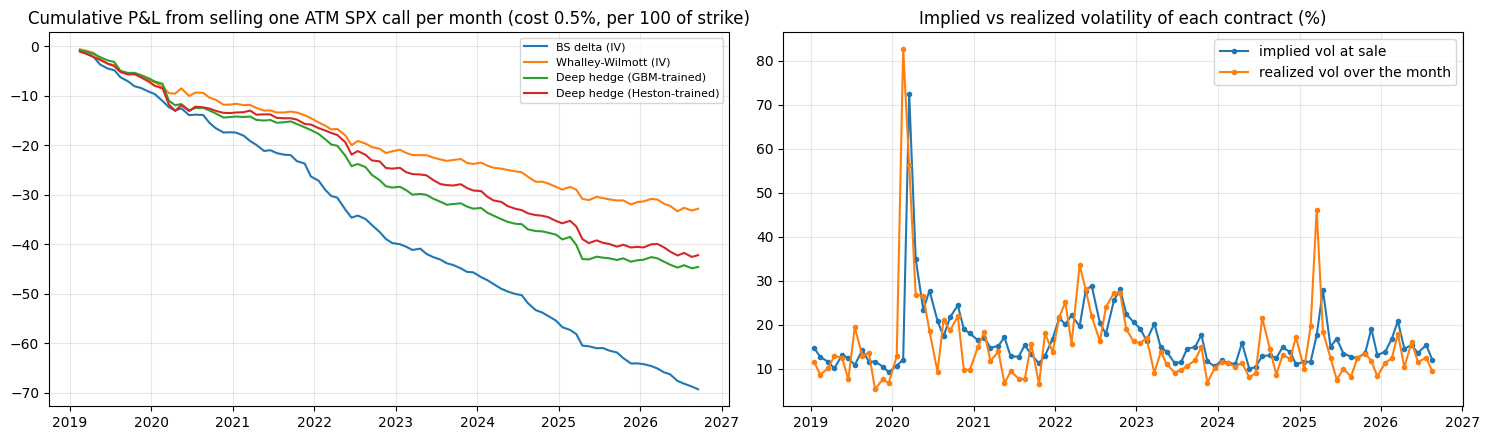

Average implied vol 16.6% vs average realized 15.6% -> the option market charged for more volatility than occurred in 74% of months.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [14]:
c = 0.005
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
for name in ["BS delta (IV)", "Whalley-Wilmott (IV)", "Deep hedge (GBM-trained)", "Deep hedge (Heston-trained)"]:
    ax[0].plot(real.expiry_day, np.cumsum(premium - store[c][name]["loss"]), label=name)
ax[0].set_title("Cumulative P&L from selling one ATM SPX call per month (cost 0.5%, per 100 of strike)")
ax[0].legend(fontsize=8)
realized = [np.std(np.diff(np.log(s))) * np.sqrt(TRADING_DAYS) for s in S_real]
ax[1].plot(real.sale_date, real["iv"] * 100, "o-", ms=3, label="implied vol at sale")
ax[1].plot(real.sale_date, np.array(realized) * 100, "o-", ms=3, label="realized vol over the month")
ax[1].set_title("Implied vs realized volatility of each contract (%)"); ax[1].legend()
plt.tight_layout(); plt.savefig("figures/p2b_01_real_spx_pnl.png", dpi=150); plt.show()
print(f"Average implied vol {real['iv'].mean():.1%} vs average realized {np.mean(realized):.1%} "
      f"-> the option market charged for more volatility than occurred in {np.mean(real['iv'].values > realized):.0%} of months.")

**How to read this.** All hedges receive the same premium, so differences in P&L come only from the hedging. The "No hedge" row shows
why hedging matters: without it, a few large rallies dominate. A positive average P&L for every hedge reflects the **volatility risk
premium** (implied volatility above realized volatility), which we already saw in the Phase II EDA, now measured on real contract prices.

Each month is an independent contract (no overlap), but there are only about 90 of them, so differences of a few percent between
hedges are not statistically meaningful; the comparison of tail risk (CVaR, worst month) is the most informative.

## 8. Summary (auto-generated) and saving the data

In [15]:
lines = [f"{len(real)} real SPX monthly ATM calls, {real.sale_date.min().date()} to {real.expiry_day.max().date()}; "
         f"average implied vol {real['iv'].mean():.1%}, average bid-ask spread {real['rel_spread'].mean():.1%} of the price."]
for c in COSTS:
    t = real_pnl.xs(c)
    best = t["CVaR 95% of loss after premium"].drop("No hedge").idxmin()
    lines.append(f"[cost {c:.1%}] lowest tail risk: {best} (CVaR {t.loc[best, 'CVaR 95% of loss after premium']:.3f}). "
                 + "; ".join(f"{s}: mean P&L {t.loc[s, 'mean P&L']:+.3f}, CVaR {t.loc[s, 'CVaR 95% of loss after premium']:.3f}"
                             for s in ["BS delta (IV)", "Whalley-Wilmott (IV)", "Deep hedge (GBM-trained)", "Deep hedge (Heston-trained)"]))
lines.append(f"Databento: downloaded ${spent['downloaded']:.4f} this run; {spent['cache_hits']} requests served from cache.")
print("\n".join(lines))
with open("results/real_spx_summary.txt", "w") as f: f.write("\n".join(lines))

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

92 real SPX monthly ATM calls, 2019-01-16 to 2026-09-18; average implied vol 16.6%, average bid-ask spread 1.0% of the price.
[cost 0.1%] lowest tail risk: Whalley-Wilmott (IV) (CVaR 1.124). BS delta (IV): mean P&L -0.009, CVaR 1.223; Whalley-Wilmott (IV): mean P&L +0.038, CVaR 1.124; Deep hedge (GBM-trained): mean P&L -0.007, CVaR 1.791; Deep hedge (Heston-trained): mean P&L -0.015, CVaR 1.481
[cost 0.5%] lowest tail risk: Whalley-Wilmott (IV) (CVaR 1.600). BS delta (IV): mean P&L -0.753, CVaR 2.148; Whalley-Wilmott (IV): mean P&L -0.356, CVaR 1.600; Deep hedge (GBM-trained): mean P&L -0.484, CVaR 2.447; Deep hedge (Heston-trained): mean P&L -0.458, CVaR 2.207
Databento: downloaded $1.0503 this run; 0 requests served from cache.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [16]:
# Download the cache (so you never pay again) plus results and figures
!zip -qr phase2b_outputs.zip data/raw/databento results/real_spx_* figures/p2b_*
from google.colab import files
files.download("phase2b_outputs.zip")

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

<IPython.core.display.Javascript object>

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


<IPython.core.display.Javascript object>

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag